In [4]:
GAMMA = 0.9    # Faktor diskonto
THETA = 0.1   # Batas perubahan nilai untuk berhenti
MDP = {
    "Rumah":   [("Jalan raya", "Kampus", 4),
                ("Jalan alternatif", "Simpang", 0)],
    "Simpang": [("Lanjut", "Kampus", 10)],
    "Kampus":  [],
}

def nilai_aksi(V, reward, tujuan, gamma):
    """Reward langsung ditambah nilai masa depan yang didiskon."""
    return reward + gamma * V[tujuan]

def perbarui_nilai(mdp, V, gamma):
    """Satu iterasi: hitung nilai baru semua state dari nilai lama."""
    V_baru, delta = {}, 0.0
    for state, aksi_list in mdp.items():
        if not aksi_list:
            V_baru[state] = 0.0          # state terminal selalu bernilai 0
        else:
            V_baru[state] = max(         # nilai state = nilai aksi terbaik
                nilai_aksi(V, reward, tujuan, gamma)
                for nama, tujuan, reward in aksi_list
            )
        delta = max(delta, abs(V_baru[state] - V[state]))
    return V_baru, delta

def value_iteration(mdp, gamma, theta):
    """Ulangi pembaruan sampai perubahan terbesar < theta."""
    V = {s: 0.0 for s in mdp}            # nilai awal semua state = 0
    riwayat = [V.copy()]
    k = 0
    while True:
        V, delta = perbarui_nilai(mdp, V, gamma)
        k += 1
        riwayat.append(V.copy())
        if delta < theta:
            break
    return V, riwayat, k

def ambil_policy(mdp, V, gamma):
    """Pada tiap state, pilih aksi dengan nilai terbesar."""
    policy = {}
    for state, aksi_list in mdp.items():
        if aksi_list:
            terbaik = max(aksi_list, key=lambda a: nilai_aksi(V, a[2], a[1], gamma))
            policy[state] = terbaik[0]
    return policy

V_opt, riwayat, k = value_iteration(MDP, GAMMA, THETA)
policy_opt = ambil_policy(MDP, V_opt, GAMMA)

In [5]:
print("Nilai optimal:", V_opt)
print("Policy optimal:", policy_opt)
print("Jumlah iterasi:", k)

Nilai optimal: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}
Policy optimal: {'Rumah': 'Jalan alternatif', 'Simpang': 'Lanjut'}
Jumlah iterasi: 3


In [ ]:
print("Riwayat nilai setiap iterasi:")
for i, nilai in enumerate(riwayat):
    print(f"Iterasi {i}: { {k: round(v, 2) for k, v in nilai.items()} }")

Riwayat nilai setiap iterasi:
Iterasi 0: {'Rumah': 0.0, 'Simpang': 0.0, 'Kampus': 0.0}
Iterasi 1: {'Rumah': 4.0, 'Simpang': 10.0, 'Kampus': 0.0}
Iterasi 2: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}
Iterasi 3: {'Rumah': 9.0, 'Simpang': 10.0, 'Kampus': 0.0}


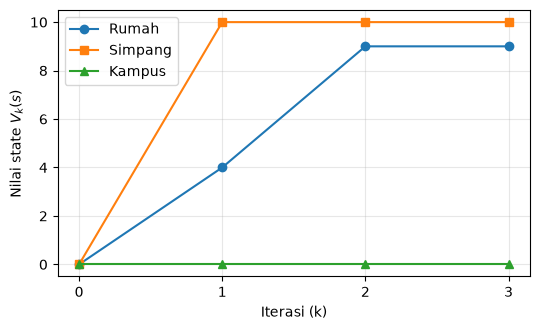

In [7]:
import matplotlib.pyplot as plt

iterasi = list(range(len(riwayat)))
plt.figure(figsize=(5.5, 3.4))
for state, penanda in [("Rumah", "o"), ("Simpang", "s"), ("Kampus", "^")]:
    plt.plot(iterasi, [v[state] for v in riwayat], marker=penanda, label=state)
plt.xlabel("Iterasi (k)")
plt.ylabel(r"Nilai state $V_k(s)$")
plt.xticks(iterasi)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()